In [1]:
#from google.colab import drive
#drive.mount('/content/drive')

In [2]:
!git clone --depth 1 https://github.com/WSU-AI-in-ME/ai-in-me-1.git

Cloning into 'ai-in-me-1'...
remote: Enumerating objects: 430, done.
remote: Counting objects: 100% (430/430), done.
remote: Compressing objects: 100% (410/410), done.
remote: Total 430 (delta 5), reused 377 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (430/430), 74.73 MiB | 12.54 MiB/s, done.
Resolving deltas: 100% (5/5), done.
Updating files: 100% (354/354), done.


In [3]:
from pathlib import Path
root = Path("/content/ai-in-me-1/data/mimii")
wav_file = list(root.rglob("*.wav"))
print("wav file:", len(wav_file))
for path in wav_file[:10]:
  print(path)


wav file: 220
/content/ai-in-me-1/data/mimii/audio/valve/id_06/normal/00000650.wav
/content/ai-in-me-1/data/mimii/audio/valve/id_06/normal/00000704.wav
/content/ai-in-me-1/data/mimii/audio/valve/id_06/normal/00000667.wav
/content/ai-in-me-1/data/mimii/audio/valve/id_06/normal/00000625.wav
/content/ai-in-me-1/data/mimii/audio/valve/id_06/normal/00000663.wav
/content/ai-in-me-1/data/mimii/audio/valve/id_06/normal/00000623.wav
/content/ai-in-me-1/data/mimii/audio/valve/id_06/normal/00000073.wav
/content/ai-in-me-1/data/mimii/audio/valve/id_06/normal/00000653.wav
/content/ai-in-me-1/data/mimii/audio/valve/id_06/normal/00000074.wav
/content/ai-in-me-1/data/mimii/audio/valve/id_06/normal/00000699.wav


In [4]:
from pathlib import Path
root = Path("/content/aiin-me-1/data/mimii")
wav_file = list(root.rglob("*.wav"))
print("wav file:", len(wav_file))
for path in wav_file[:10]:
  print(path)


wav file: 0


In [5]:
from pathlib import Path

root = Path("/content/ai-in-me-1/data/mimii")

print("Folder exists:", root.exists())
if root.exists():
    for item in root.iterdir():
        print(item.name, "— folder" if item.is_dir() else "— file")

Folder exists: True
README.md — file
audio — folder
features — folder
LICENSE_DATA.txt — file
metadata.csv — file


In [6]:
audio_root = root / "audio"
files = list(audio_root.rglob("*"))

print("Files found:", sum(path.is_file() for path in files))
for path in files[:20]:
    if path.is_file():
        print(path.relative_to(root))

Files found: 220


In [7]:
from pathlib import Path
import pandas as pd

audio_root = root / "audio"
wav_files = sorted(audio_root.rglob("*.wav"))

print("WAV files:", len(wav_files))
for path in wav_files[:8]:
    print(path.relative_to(root))

metadata = pd.read_csv(root / "metadata.csv")
print("\nMetadata columns:")
print(metadata.columns.tolist())
print("\nFirst 5 metadata rows:")
display(metadata.head())

WAV files: 220
audio/fan/id_00/normal/00000025.wav
audio/fan/id_00/normal/00000026.wav
audio/fan/id_00/normal/00000114.wav
audio/fan/id_00/normal/00000116.wav
audio/fan/id_00/normal/00000281.wav
audio/fan/id_00/normal/00000284.wav
audio/fan/id_00/normal/00000654.wav
audio/fan/id_00/normal/00000658.wav

Metadata columns:
['recording_id', 'file_path', 'source_file', 'machine_type', 'machine_id', 'condition', 'classification_included', 'anomaly_included', 'snr_db', 'channel', 'sample_rate', 'duration_seconds', 'num_samples', 'sha256']

First 5 metadata rows:


,recording_id,file_path,source_file,machine_type,machine_id,condition,classification_included,anomaly_included,snr_db,channel,sample_rate,duration_seconds,num_samples,sha256
0,fan_id_00_normal_00000025_80da26572c,audio/fan/id_00/normal/00000025.wav,0_dB_fan/fan/id_00/normal/00000025.wav,fan,id_00,normal,True,False,0,microphone_channel_1,16000,10.0,160000,c96df6c199b4a8be27c826fa565ca148e59d3a8acbfae5...
1,fan_id_00_normal_00000026_7683cb94c3,audio/fan/id_00/normal/00000026.wav,0_dB_fan/fan/id_00/normal/00000026.wav,fan,id_00,normal,True,False,0,microphone_channel_1,16000,10.0,160000,ef81f8f010023bf96a0afc3eb8f0300ce50c2d7897c534...
2,fan_id_00_normal_00000114_d54f14163d,audio/fan/id_00/normal/00000114.wav,0_dB_fan/fan/id_00/normal/00000114.wav,fan,id_00,normal,True,False,0,microphone_channel_1,16000,10.0,160000,6971e66bdbe0226c2e395a99ab040cb43f2773fc3e14b8...
3,fan_id_00_normal_00000116_40dc056a77,audio/fan/id_00/normal/00000116.wav,0_dB_fan/fan/id_00/normal/00000116.wav,fan,id_00,normal,True,False,0,microphone_channel_1,16000,10.0,160000,27e39f69a2d0077ba8e79ef38d8da625eee4bb7a6c9637...
4,fan_id_00_normal_00000281_6806346013,audio/fan/id_00/normal/00000281.wav,0_dB_fan/fan/id_00/normal/00000281.wav,fan,id_00,normal,True,False,0,microphone_channel_1,16000,10.0,160000,271b6d2c616ef3cb386d0f94c7156d61840b37aecb2115...


In [8]:
anomaly_data = metadata[metadata["anomaly_included"] == True]

print("Anomaly-task recordings:", len(anomaly_data))
print("\nCounts by machine and condition:")
display(
    anomaly_data.groupby(["machine_type", "machine_id", "condition"])
    .size()
    .rename("recordings")
    .reset_index()
)

print("\nExample audio paths:")
display(anomaly_data[["file_path", "condition"]].head(10))

Anomaly-task recordings: 70

Counts by machine and condition:


,machine_type,machine_id,condition,recordings
0,fan,id_06,anomaly,20
1,fan,id_06,normal,50



Example audio paths:


,file_path,condition
30,audio/fan/id_06/anomaly/00000024.wav,anomaly
31,audio/fan/id_06/anomaly/00000046.wav,anomaly
32,audio/fan/id_06/anomaly/00000056.wav,anomaly
33,audio/fan/id_06/anomaly/00000070.wav,anomaly
34,audio/fan/id_06/anomaly/00000078.wav,anomaly
35,audio/fan/id_06/anomaly/00000081.wav,anomaly
36,audio/fan/id_06/anomaly/00000112.wav,anomaly
37,audio/fan/id_06/anomaly/00000126.wav,anomaly
38,audio/fan/id_06/anomaly/00000134.wav,anomaly
39,audio/fan/id_06/anomaly/00000185.wav,anomaly


Conditions: ['anomaly' 'normal']


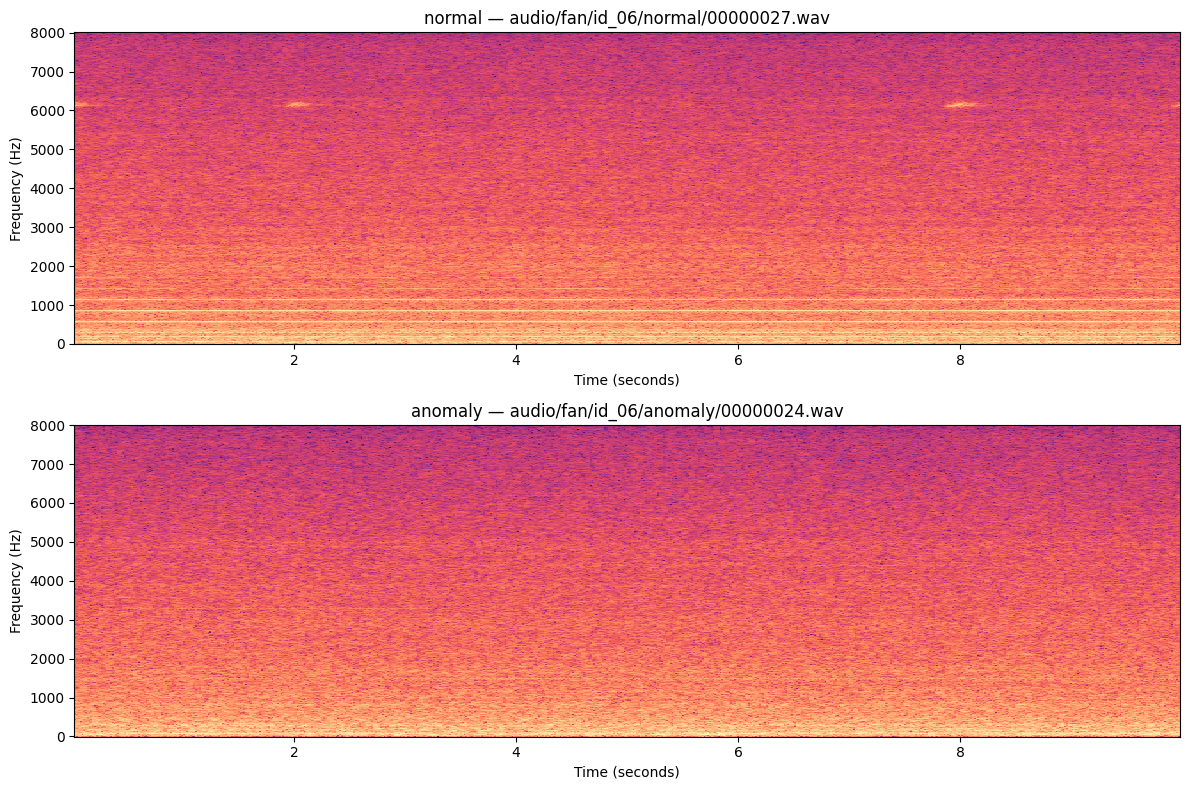

In [9]:
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import spectrogram
import numpy as np

print("Conditions:", anomaly_data["condition"].unique())

normal_row = anomaly_data[anomaly_data["condition"] == "normal"].iloc[0]
faulty_label = next(
    label for label in anomaly_data["condition"].unique()
    if label != "normal"
)
faulty_row = anomaly_data[anomaly_data["condition"] == faulty_label].iloc[0]

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

for ax, row in zip(axes, [normal_row, faulty_row]):
    sample_rate, audio = wavfile.read(root / row["file_path"])
    audio = audio.astype(np.float32)
    frequencies, times, power = spectrogram(
        audio, fs=sample_rate, nperseg=1024, noverlap=768
    )
    power_db = 10 * np.log10(power + 1e-12)

    ax.pcolormesh(times, frequencies, power_db, shading="auto", cmap="magma")
    ax.set_title(f'{row["condition"]} — {row["file_path"]}')
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

In [10]:
print(
    anomaly_data["condition"]
    .value_counts()
    .rename_axis("condition")
    .to_frame("recordings")
)

           recordings
condition            
normal             50
anomaly            20


In [11]:
!pip -q install librosa scikit-learn


In [12]:
import librosa
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

def extract_features(file_path):
    audio, sr = librosa.load(root / file_path, sr=None, mono=True)

    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=20)
    rms = librosa.feature.rms(y=audio)
    centroid = librosa.feature.spectral_centroid(y=audio, sr=sr)
    zcr = librosa.feature.zero_crossing_rate(y=audio)

    # Summarize each feature across time: mean and standard deviation
    return np.concatenate([
        mfcc.mean(axis=1), mfcc.std(axis=1),
        [rms.mean(), rms.std()],
        [centroid.mean(), centroid.std()],
        [zcr.mean(), zcr.std()],
    ])

X = np.stack([
    extract_features(path)
    for path in anomaly_data["file_path"]
])

# normal = 0, anomaly = 1
y = (anomaly_data["condition"] == "anomaly").astype(int).to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print(classification_report(
    y_test, predictions,
    labels=[0, 1],
    target_names=["normal", "anomaly"],
    zero_division=0
))
print("Confusion matrix (true rows, predicted columns):")
print(confusion_matrix(y_test, predictions, labels=[0, 1]))

              precision    recall  f1-score   support

      normal       0.83      1.00      0.91        15
     anomaly       1.00      0.50      0.67         6

    accuracy                           0.86        21
   macro avg       0.92      0.75      0.79        21
weighted avg       0.88      0.86      0.84        21

Confusion matrix (true rows, predicted columns):
[[15  0]
 [ 3  3]]


In [13]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix


indices = np.arange(len(y))
train_idx, test_idx = train_test_split(
    indices, test_size=0.30, random_state=42, stratify=y
)


spectrograms = []

for file_path in anomaly_data["file_path"]:
    audio, sr = librosa.load(root / file_path, sr=None, mono=True)
    mel = librosa.feature.melspectrogram(
        y=audio, sr=sr, n_fft=1024, hop_length=256, n_mels=64
    )
    log_mel = librosa.power_to_db(mel + 1e-10, ref=np.max)
    spectrograms.append(log_mel)


X_spec = np.array(spectrograms, dtype=np.float32)[:, None, :, :]


mean = X_spec[train_idx].mean()
std = X_spec[train_idx].std() + 1e-6
X_spec = (X_spec - mean) / std

X_train_t = torch.tensor(X_spec[train_idx])
X_test_t = torch.tensor(X_spec[test_idx])
y_train_t = torch.tensor(y[train_idx], dtype=torch.long)
y_test_t = torch.tensor(y[test_idx], dtype=torch.long)

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t), batch_size=8, shuffle=True
)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(32, 2),
        )

    def forward(self, x):
        return self.layers(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn = SmallCNN().to(device)


class_counts = np.bincount(y[train_idx], minlength=2)
weights = torch.tensor(
    len(train_idx) / (2 * class_counts),
    dtype=torch.float32,
    device=device
)
loss_fn = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.Adam(cnn.parameters(), lr=0.001)

for epoch in range(20):
    cnn.train()
    total_loss = 0

    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)

        optimizer.zero_grad()
        loss = loss_fn(cnn(batch_x), batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch + 1:02d}/20 — loss: {total_loss / len(train_loader):.4f}")

cnn.eval()
with torch.no_grad():
    logits = cnn(X_test_t.to(device))
    cnn_predictions = logits.argmax(dim=1).cpu().numpy()

print(classification_report(
    y[test_idx], cnn_predictions,
    labels=[0, 1],
    target_names=["normal", "anomaly"],
    zero_division=0
))
print("Confusion matrix (true rows, predicted columns):")
print(confusion_matrix(y[test_idx], cnn_predictions, labels=[0, 1]))

Epoch 01/20 — loss: 0.7235
Epoch 02/20 — loss: 0.6804
Epoch 03/20 — loss: 0.6778
Epoch 04/20 — loss: 0.6672
Epoch 05/20 — loss: 0.6705
Epoch 06/20 — loss: 0.6648
Epoch 07/20 — loss: 0.7122
Epoch 08/20 — loss: 0.6672
Epoch 09/20 — loss: 0.6690
Epoch 10/20 — loss: 0.6642
Epoch 11/20 — loss: 0.6592
Epoch 12/20 — loss: 0.6569
Epoch 13/20 — loss: 0.6599
Epoch 14/20 — loss: 0.6564
Epoch 15/20 — loss: 0.6619
Epoch 16/20 — loss: 0.7030
Epoch 17/20 — loss: 0.6573
Epoch 18/20 — loss: 0.6562
Epoch 19/20 — loss: 0.6512
Epoch 20/20 — loss: 0.6875
              precision    recall  f1-score   support

      normal       0.71      1.00      0.83        15
     anomaly       0.00      0.00      0.00         6

    accuracy                           0.71        21
   macro avg       0.36      0.50      0.42        21
weighted avg       0.51      0.71      0.60        21

Confusion matrix (true rows, predicted columns):
[[15  0]
 [ 6  0]]


In [14]:
cnn.eval()

with torch.no_grad():
    train_logits = cnn(X_train_t.to(device))
    train_predictions = train_logits.argmax(dim=1).cpu().numpy()

print("CNN — training results:")
print(classification_report(
    y[train_idx], train_predictions,
    labels=[0, 1],
    target_names=["normal", "anomaly"],
    zero_division=0
))

with torch.no_grad():
    anomaly_probabilities = torch.softmax(
        cnn(X_test_t.to(device)), dim=1
    )[:, 1].cpu().numpy()

print("\nTest recordings and predicted anomaly probabilities:")
for position, probability in zip(test_idx, anomaly_probabilities):
    row = anomaly_data.iloc[position]
    print(
        f"true={row['condition']:8s}  "
        f"anomaly_probability={probability:.3f}  "
        f"{row['file_path']}"
    )

CNN — training results:
              precision    recall  f1-score   support

      normal       0.71      1.00      0.83        35
     anomaly       0.00      0.00      0.00        14

    accuracy                           0.71        49
   macro avg       0.36      0.50      0.42        49
weighted avg       0.51      0.71      0.60        49


Test recordings and predicted anomaly probabilities:
true=normal    anomaly_probability=0.402  audio/fan/id_06/normal/00000408.wav
true=normal    anomaly_probability=0.399  audio/fan/id_06/normal/00000413.wav
true=anomaly   anomaly_probability=0.387  audio/fan/id_06/anomaly/00000219.wav
true=normal    anomaly_probability=0.400  audio/fan/id_06/normal/00000970.wav
true=normal    anomaly_probability=0.391  audio/fan/id_06/normal/00000335.wav
true=anomaly   anomaly_probability=0.378  audio/fan/id_06/anomaly/00000134.wav
true=normal    anomaly_probability=0.405  audio/fan/id_06/normal/00000868.wav
true=normal    anomaly_probability=0.391  audio

In [15]:
from sklearn.model_selection import train_test_split


fit_idx, val_idx = train_test_split(
    train_idx,
    test_size=0.20,
    random_state=7,
    stratify=y[train_idx]
)

for name, indices_part in [
    ("Fit", fit_idx),
    ("Validation", val_idx),
    ("Test — keep untouched", test_idx),
]:
    labels, counts = np.unique(y[indices_part], return_counts=True)
    print(name, dict(zip(labels, counts)))

Fit {np.int64(0): np.int64(28), np.int64(1): np.int64(11)}
Validation {np.int64(0): np.int64(7), np.int64(1): np.int64(3)}
Test — keep untouched {np.int64(0): np.int64(15), np.int64(1): np.int64(6)}


In [16]:
import copy
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import classification_report, confusion_matrix


X_raw = np.asarray(spectrograms, dtype=np.float32)[:, None, :, :]
fit_mean = X_raw[fit_idx].mean()
fit_std = X_raw[fit_idx].std() + 1e-6
X_norm = (X_raw - fit_mean) / fit_std

class SpecDataset(Dataset):
    def __init__(self, indices, augment=False):
        self.indices = indices
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        index = self.indices[i]
        x = torch.tensor(X_norm[index], dtype=torch.float32)
        label = torch.tensor(y[index], dtype=torch.long)


        if self.augment:
            x = x.clone()
            freq_width = np.random.randint(0, 9)
            time_width = np.random.randint(0, 41)

            if freq_width:
                start = np.random.randint(0, x.shape[1] - freq_width + 1)
                x[:, start:start + freq_width, :] = 0

            if time_width:
                start = np.random.randint(0, x.shape[2] - time_width + 1)
                x[:, :, start:start + time_width] = 0

        return x, label

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(32, 2),
        )

    def forward(self, x):
        return self.layers(x)

torch.manual_seed(42)
np.random.seed(42)

fit_loader = DataLoader(
    SpecDataset(fit_idx, augment=True), batch_size=8, shuffle=True
)
val_loader = DataLoader(
    SpecDataset(val_idx), batch_size=8, shuffle=False
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn = SmallCNN().to(device)

counts = np.bincount(y[fit_idx], minlength=2)
class_weights = torch.tensor(
    len(fit_idx) / (2 * counts), dtype=torch.float32, device=device
)
loss_fn = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(cnn.parameters(), lr=0.001, weight_decay=1e-4)

best_val_loss = float("inf")
best_state = None
patience = 8
epochs_without_improvement = 0

for epoch in range(40):
    cnn.train()
    for batch_x, batch_y in fit_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(cnn(batch_x), batch_y)
        loss.backward()
        optimizer.step()

    cnn.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            val_loss += loss_fn(cnn(batch_x), batch_y).item() * len(batch_y)
    val_loss /= len(val_idx)
    print(f"Epoch {epoch + 1:02d} — validation loss: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(cnn.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping.")
            break

cnn.load_state_dict(best_state)


Epoch 01 — validation loss: 0.6931
Epoch 02 — validation loss: 0.6942
Epoch 03 — validation loss: 0.6943
Epoch 04 — validation loss: 0.6941
Epoch 05 — validation loss: 0.6925
Epoch 06 — validation loss: 0.6906
Epoch 07 — validation loss: 0.6932
Epoch 08 — validation loss: 0.6968
Epoch 09 — validation loss: 0.6958
Epoch 10 — validation loss: 0.6949
Epoch 11 — validation loss: 0.6976
Epoch 12 — validation loss: 0.6970
Epoch 13 — validation loss: 0.6958
Epoch 14 — validation loss: 0.6936
Early stopping.


<All keys matched successfully>

In [17]:
cnn.eval()

with torch.no_grad():
    val_logits = cnn(
        torch.tensor(X_norm[val_idx], dtype=torch.float32).to(device)
    )
    val_predictions = val_logits.argmax(dim=1).cpu().numpy()
    val_anomaly_probs = torch.softmax(val_logits, dim=1)[:, 1].cpu().numpy()

print(classification_report(
    y[val_idx], val_predictions,
    labels=[0, 1],
    target_names=["normal", "anomaly"],
    zero_division=0
))
print("Confusion matrix (true rows, predicted columns):")
print(confusion_matrix(y[val_idx], val_predictions, labels=[0, 1]))

print("\nValidation recordings:")
for position, probability in zip(val_idx, val_anomaly_probs):
    row = anomaly_data.iloc[position]
    print(f"true={row['condition']:8s} probability={probability:.3f} {row['file_path']}")

              precision    recall  f1-score   support

      normal       0.70      1.00      0.82         7
     anomaly       0.00      0.00      0.00         3

    accuracy                           0.70        10
   macro avg       0.35      0.50      0.41        10
weighted avg       0.49      0.70      0.58        10

Confusion matrix (true rows, predicted columns):
[[7 0]
 [3 0]]

Validation recordings:
true=normal   probability=0.462 audio/fan/id_06/normal/00000676.wav
true=anomaly  probability=0.467 audio/fan/id_06/anomaly/00000185.wav
true=normal   probability=0.441 audio/fan/id_06/normal/00000068.wav
true=normal   probability=0.459 audio/fan/id_06/normal/00000391.wav
true=normal   probability=0.453 audio/fan/id_06/normal/00000218.wav
true=normal   probability=0.445 audio/fan/id_06/normal/00000910.wav
true=anomaly  probability=0.460 audio/fan/id_06/anomaly/00000056.wav
true=normal   probability=0.455 audio/fan/id_06/normal/00000226.wav
true=normal   probability=0.451 audio/f

In [18]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

scores = cross_validate(
    rf,
    X,
    y,
    cv=cv,
    scoring={
        "anomaly_recall": "recall",
        "anomaly_f1": "f1",
        "balanced_accuracy": "balanced_accuracy",
    },
    n_jobs=-1
)

for metric in ["anomaly_recall", "anomaly_f1", "balanced_accuracy"]:
    values = scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.3f} ± {values.std():.3f}")

anomaly_recall: 0.690 ± 0.227
anomaly_f1: 0.793 ± 0.180
balanced_accuracy: 0.845 ± 0.113


In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

one_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_predictions = cross_val_predict(
    rf, X, y, cv=one_cv, n_jobs=-1
)

print(classification_report(
    y, oof_predictions,
    labels=[0, 1],
    target_names=["normal", "anomaly"],
    zero_division=0
))
print("Confusion matrix (true rows, predicted columns):")
print(confusion_matrix(y, oof_predictions, labels=[0, 1]))

rows = anomaly_data.reset_index(drop=True)
missed = rows[(y == 1) & (oof_predictions == 0)]
print("\nAnomalies missed in this cross-validation run:")
display(missed[["file_path", "condition"]])

              precision    recall  f1-score   support

      normal       0.91      1.00      0.95        50
     anomaly       1.00      0.75      0.86        20

    accuracy                           0.93        70
   macro avg       0.95      0.88      0.90        70
weighted avg       0.94      0.93      0.93        70

Confusion matrix (true rows, predicted columns):
[[50  0]
 [ 5 15]]

Anomalies missed in this cross-validation run:


,file_path,condition
1,audio/fan/id_06/anomaly/00000046.wav,anomaly
8,audio/fan/id_06/anomaly/00000134.wav,anomaly
9,audio/fan/id_06/anomaly/00000185.wav,anomaly
10,audio/fan/id_06/anomaly/00000204.wav,anomaly
11,audio/fan/id_06/anomaly/00000219.wav,anomaly


In [20]:
import pandas as pd

feature_names = (
    [f"mfcc_mean_{i+1}" for i in range(20)]
    + [f"mfcc_std_{i+1}" for i in range(20)]
    + ["rms_mean", "rms_std"]
    + ["centroid_mean", "centroid_std"]
    + ["zcr_mean", "zcr_std"]
)

rf.fit(X, y)

importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

display(importance.head(10))

,feature,importance
40,rms_mean,0.156008
18,mfcc_mean_19,0.143993
7,mfcc_mean_8,0.039737
38,mfcc_std_19,0.037219
19,mfcc_mean_20,0.037029
0,mfcc_mean_1,0.031553
34,mfcc_std_15,0.029308
4,mfcc_mean_5,0.027210
26,mfcc_std_7,0.026017
45,zcr_std,0.025319


In [21]:
from google.colab import drive
from pathlib import Path
import joblib

drive.mount("/content/drive")

model_folder = Path("/content/drive/MyDrive/machine_fault_detection/models")
model_folder.mkdir(parents=True, exist_ok=True)

model_path = model_folder / "rf_fan_id06.joblib"

joblib.dump(
    {
        "model": rf,
        "feature_names": feature_names,
        "machine_type": "fan",
        "machine_id": "id_06",
        "sample_rate": 16000,
        "duration_seconds": 10,
    },
    model_path
)

print("Saved model to:", model_path)

Mounted at /content/drive
Saved model to: /content/drive/MyDrive/machine_fault_detection/models/rf_fan_id06.joblib


In [22]:
from google.colab import files
#files.download(str(model_path))

In [23]:
from pathlib import Path
from google.colab import files

root = Path("/content/ai-in-me-1/data/mimii")
sample_path = root / "audio/fan/id_06/normal/00000676.wav"



In [24]:
from google.colab import files

sample_path = root / "audio/fan/id_06/anomaly/00000046.wav"
files.download(str(sample_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
from sklearn.ensemble import RandomForestClassifier
import joblib


rf_holdout = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)
rf_holdout.fit(X_train, y_train)

joblib.dump(
    {
        "model": rf_holdout,
        "feature_names": feature_names,
        "machine_type": "fan",
        "machine_id": "id_06",
        "sample_rate": 16000,
        "duration_seconds": 10,
    },
    model_path
)

print("Saved training-split model to:", model_path)


Saved training-split model to: /content/drive/MyDrive/machine_fault_detection/models/rf_fan_id06.joblib


In [26]:
from google.colab import files

heldout_rows = anomaly_data.iloc[test_idx]
sample_row = heldout_rows[heldout_rows["condition"] == "anomaly"].iloc[0]

print("Held-out sample:", sample_row["file_path"])
#files.download(str(root / sample_row["file_path"]))

Held-out sample: audio/fan/id_06/anomaly/00000219.wav


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
from google.colab import files

normal_row = heldout_rows[heldout_rows["condition"] == "normal"].iloc[0]
print("Held-out normal:", normal_row["file_path"])
#files.download(str(root / normal_row["file_path"]))

Held-out normal: audio/fan/id_06/normal/00000408.wav


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
from sklearn.metrics import classification_report, confusion_matrix

test_predictions = rf_holdout.predict(X_test)

print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["normal", "anomaly"],
    zero_division=0
))
print("Confusion matrix (true rows, predicted columns):")
print(confusion_matrix(y_test, test_predictions, labels=[0, 1]))

              precision    recall  f1-score   support

      normal       0.83      1.00      0.91        15
     anomaly       1.00      0.50      0.67         6

    accuracy                           0.86        21
   macro avg       0.92      0.75      0.79        21
weighted avg       0.88      0.86      0.84        21

Confusion matrix (true rows, predicted columns):
[[15  0]
 [ 3  3]]


In [29]:
heldout_rows = anomaly_data.iloc[test_idx].reset_index(drop=True)

missed_test_anomalies = heldout_rows[
    (y_test == 1) & (test_predictions == 0)
]

display(missed_test_anomalies[["file_path", "condition"]])

,file_path,condition
2,audio/fan/id_06/anomaly/00000219.wav,anomaly
5,audio/fan/id_06/anomaly/00000134.wav,anomaly
10,audio/fan/id_06/anomaly/00000046.wav,anomaly


In [30]:
#from google.colab import files
#files.download(str(model_path))

In [31]:
import copy
import librosa
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import classification_report, confusion_matrix


specs = []
for file_path in anomaly_data["file_path"]:
    audio, sr = librosa.load(root / file_path, sr=None, mono=True)
    mel = librosa.feature.melspectrogram(
        y=audio, sr=sr, n_fft=1024, hop_length=256, n_mels=64
    )
    specs.append(librosa.power_to_db(mel + 1e-10, ref=1.0))

X_cnn = np.asarray(specs, dtype=np.float32)[:, None, :, :]


mean = X_cnn[fit_idx].mean()
std = X_cnn[fit_idx].std() + 1e-6
X_cnn = (X_cnn - mean) / std

fit_data = TensorDataset(
    torch.tensor(X_cnn[fit_idx]),
    torch.tensor(y[fit_idx], dtype=torch.long),
)
val_x = torch.tensor(X_cnn[val_idx])
val_y = torch.tensor(y[val_idx], dtype=torch.long)
train_loader = DataLoader(fit_data, batch_size=8, shuffle=True)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(64, 2),
        )

    def forward(self, x):
        return self.layers(x)

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn = SmallCNN().to(device)

counts = np.bincount(y[fit_idx], minlength=2)
weights = torch.tensor(
    len(fit_idx) / (2 * counts), dtype=torch.float32, device=device
)
loss_fn = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.AdamW(cnn.parameters(), lr=0.001, weight_decay=1e-4)

best_loss = float("inf")
best_state = None
wait = 0

for epoch in range(60):
    cnn.train()
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(cnn(batch_x), batch_y)
        loss.backward()
        optimizer.step()

    cnn.eval()
    with torch.no_grad():
        val_loss = loss_fn(
            cnn(val_x.to(device)), val_y.to(device)
        ).item()

    print(f"Epoch {epoch + 1:02d} — validation loss: {val_loss:.4f}")

    if val_loss < best_loss:
        best_loss = val_loss
        best_state = copy.deepcopy(cnn.state_dict())
        wait = 0
    else:
        wait += 1
        if wait >= 10:
            print("Early stopping.")
            break

cnn.load_state_dict(best_state)
cnn.eval()
with torch.no_grad():
    val_predictions = cnn(val_x.to(device)).argmax(1).cpu().numpy()

print(classification_report(
    y[val_idx], val_predictions,
    labels=[0, 1],
    target_names=["normal", "anomaly"],
    zero_division=0,
))
print("Confusion matrix:")
print(confusion_matrix(y[val_idx], val_predictions, labels=[0, 1]))

Epoch 01 — validation loss: 0.6944
Epoch 02 — validation loss: 0.6969
Epoch 03 — validation loss: 0.6983
Epoch 04 — validation loss: 0.7077
Epoch 05 — validation loss: 0.7049
Epoch 06 — validation loss: 0.7015
Epoch 07 — validation loss: 0.6997
Epoch 08 — validation loss: 0.7254
Epoch 09 — validation loss: 0.7319
Epoch 10 — validation loss: 0.7081
Epoch 11 — validation loss: 0.6865
Epoch 12 — validation loss: 0.7440
Epoch 13 — validation loss: 0.6790
Epoch 14 — validation loss: 0.6951
Epoch 15 — validation loss: 0.6702
Epoch 16 — validation loss: 0.6372
Epoch 17 — validation loss: 0.6485
Epoch 18 — validation loss: 0.7187
Epoch 19 — validation loss: 0.9286
Epoch 20 — validation loss: 0.6782
Epoch 21 — validation loss: 0.7570
Epoch 22 — validation loss: 0.8631
Epoch 23 — validation loss: 0.6824
Epoch 24 — validation loss: 0.7041
Epoch 25 — validation loss: 0.8485
Epoch 26 — validation loss: 0.7646
Early stopping.
              precision    recall  f1-score   support

      normal       

In [32]:
# Final evaluation on the untouched test recordings
test_x = torch.tensor(X_cnn[test_idx], dtype=torch.float32)
test_y = y[test_idx]

cnn.eval()
with torch.no_grad():
    test_logits = cnn(test_x.to(device))
    test_predictions = test_logits.argmax(dim=1).cpu().numpy()

print("Test recordings:", len(test_y))
print(classification_report(
    test_y,
    test_predictions,
    labels=[0, 1],
    target_names=["normal", "anomaly"],
    zero_division=0,
))
print("Confusion matrix (true rows, predicted columns):")
print(confusion_matrix(test_y, test_predictions, labels=[0, 1]))

Test recordings: 21
              precision    recall  f1-score   support

      normal       0.88      1.00      0.94        15
     anomaly       1.00      0.67      0.80         6

    accuracy                           0.90        21
   macro avg       0.94      0.83      0.87        21
weighted avg       0.92      0.90      0.90        21

Confusion matrix (true rows, predicted columns):
[[15  0]
 [ 2  4]]


In [33]:
import torch
from google.colab import files

checkpoint = {
    "state_dict": {
        name: tensor.detach().cpu()
        for name, tensor in cnn.state_dict().items()
    },
    "mean": float(mean),
    "std": float(std),
    "sample_rate": 16000,
    "n_fft": 1024,
    "hop_length": 256,
    "n_mels": 64,
}

torch.save(checkpoint, "cnn_fan_id06.pth")
files.download("cnn_fan_id06.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
test_probs = torch.softmax(test_logits, dim=1)[:, 1].cpu().numpy()

for i, idx in enumerate(test_idx):
    true_label = "anomaly" if int(y[idx]) == 1 else "normal"
    predicted_label = "anomaly" if int(test_predictions[i]) == 1 else "normal"
    print(
        f"true={true_label:7} predicted={predicted_label:7} "
        f"score={test_probs[i]:.1%} {anomaly_data.iloc[idx]['file_path']}"
    )

true=normal  predicted=normal  score=38.8% audio/fan/id_06/normal/00000408.wav
true=normal  predicted=normal  score=36.6% audio/fan/id_06/normal/00000413.wav
true=anomaly predicted=normal  score=28.1% audio/fan/id_06/anomaly/00000219.wav
true=normal  predicted=normal  score=40.9% audio/fan/id_06/normal/00000970.wav
true=normal  predicted=normal  score=29.9% audio/fan/id_06/normal/00000335.wav
true=anomaly predicted=normal  score=28.7% audio/fan/id_06/anomaly/00000134.wav
true=normal  predicted=normal  score=42.5% audio/fan/id_06/normal/00000868.wav
true=normal  predicted=normal  score=37.3% audio/fan/id_06/normal/00000751.wav
true=normal  predicted=normal  score=39.6% audio/fan/id_06/normal/00000253.wav
true=anomaly predicted=anomaly score=75.9% audio/fan/id_06/anomaly/00000112.wav
true=anomaly predicted=anomaly score=64.9% audio/fan/id_06/anomaly/00000046.wav
true=normal  predicted=normal  score=31.9% audio/fan/id_06/normal/00000550.wav
true=normal  predicted=normal  score=32.7% audio

In [36]:
from google.colab import files
from zipfile import ZipFile

normal_files = [
    "00000408.wav", "00000413.wav", "00000970.wav", "00000335.wav",
    "00000868.wav", "00000751.wav", "00000253.wav", "00000550.wav",
    "00000058.wav", "00000176.wav", "00000223.wav", "00000325.wav",
    "00000846.wav", "00000706.wav", "00000799.wav",
]

anomaly_files = [
    "00000219.wav", "00000134.wav", "00000112.wav",
    "00000046.wav", "00000275.wav", "00000252.wav",
]

zip_path = "/content/fan_id06_test_samples.zip"
missing = []

with ZipFile(zip_path, "w") as archive:
    for condition, filenames in [
        ("normal", normal_files),
        ("anomaly", anomaly_files),
    ]:
        for filename in filenames:
            relative_path = f"audio/fan/id_06/{condition}/{filename}"
            full_path = root / relative_path

            if full_path.exists():
                archive.write(full_path, arcname=relative_path)
            else:
                missing.append(relative_path)

print("Missing files:", missing)
files.download(zip_path)

Missing files: []


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>